# Chapter 19: Reports, Automation and Testing Your Analysis

The programs from Chapter 19 of *Data Analysis with Python, Hands-On* by Aadhavan Muthurengan, in the book's order. Each code cell is one program; the same program is in this folder as a `.py` file, and its expected output is in the `.out` file with the same name.

Run the cells from top to bottom (**Run > Run All Cells**). The programs read the datasets from `../data/`, so keep this notebook in its chapter folder.

## A Report From a Program

`report.py`

# Larkspur Home: 2025 sales report
Generated 05 January 2026.

- Revenue: $379,703 from 5,833 orders
- Best month: December ($58,888)
- Average order: $65.10

## Top products

- Floor Lamp: $69,156
- Duvet Cover: $47,971
- Cast Iron Pan: $36,798

![Revenue by month](report_revenue.png)



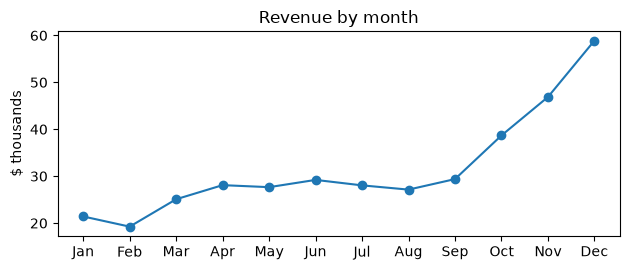

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import pandas as pd

from metrics import add_revenue, top_products

orders = add_revenue(
    pd.read_csv("../data/orders.csv", parse_dates=["order_date"])
)
monthly = orders.set_index("order_date")["revenue"].resample("MS").sum()

fig, ax = plt.subplots(figsize=(6.4, 2.8))
ax.plot(monthly.index.strftime("%b"), monthly / 1000, marker="o")
ax.set_ylabel("$ thousands")
ax.set_title("Revenue by month")
fig.tight_layout()
fig.savefig("report_revenue.png")

best = monthly.idxmax().strftime("%B")
lines = [
    "# Larkspur Home: 2025 sales report",
    f"Generated {date(2026, 1, 5):%d %B %Y}.",
    "",
    f"- Revenue: ${orders['revenue'].sum():,.0f}"
    f" from {len(orders):,} orders",
    f"- Best month: {best} (${monthly.max():,.0f})",
    f"- Average order: ${orders['revenue'].mean():.2f}",
    "",
    "## Top products",
    "",
]
for product, revenue in top_products(orders).items():
    lines.append(f"- {product}: ${revenue:,.0f}")
lines += ["", "![Revenue by month](report_revenue.png)"]

with open("report.md", "w") as f:
    f.write("\n".join(lines) + "\n")
print(open("report.md").read())